# TP 6 — Coloriage de graphes

Dans ce TP on va :
1. Explorer les outils SageMath pour le coloriage *exact* ;
2. Implémenter Welsh-Powell ;
3. Utiliser une implémentation fournie de DSatur et comparer ;
4. Appliquer les deux heuristiques sur les graphes du TD.

**SageMath ne propose pas Welsh-Powell ni DSatur en natif** — ces algorithmes n'existent pas dans la bibliothèque. On dispose en revanche d'algorithmes *exacts* (exponentiels) pour vérifier nos résultats.

## Outils SageMath disponibles

| Méthode | Description |
|---|---|
| `G.chromatic_number()` | Calcule $\chi(G)$ exactement (exponentiel) |
| `G.coloring()` | Renvoie un coloriage optimal (dict couleur → liste sommets) |
| `G.clique_number()` | Renvoie $\omega(G)$ |
| `G.clique_maximum()` | Renvoie une clique de taille maximale |
| `G.plot(vertex_colors=...)` | Affiche le graphe avec couleurs |

On les utilise uniquement pour **vérifier** nos heuristiques.

In [1]:
# Utilitaire commun : affichage colorié
from collections import defaultdict
palette = ['#e74c3c','#3498db','#2ecc71','#f39c12','#9b59b6','#1abc9c','#e67e22']

def afficher_coloriage(G, couleurs, titre='', pos=None):
    """
    Affiche un graphe G avec ses sommets coloriés
    """
    groupes = defaultdict(list)
    for v, c in couleurs.items():
        groupes[c].append(v)
    vc = {palette[(c-1) % len(palette)]: vs for c, vs in groupes.items()} #dictionnaire pour convertir les chiffres en vrai couleur
    kwargs = dict(vertex_colors=vc, title=titre)
    if pos:
        kwargs['pos'] = pos
    return G.plot(**kwargs)

## Exercice 1 — Propriétés de base

* À faire sur papier
* Vérifier vos résultats

In [2]:
P5 = graphs.PathGraph(5)
C5 = graphs.CycleGraph(5)
K4 = graphs.CompleteGraph(4)

In [3]:
# Graphe 1d) du TD : A-B-C-D avec arêtes AB, BC, CD, DA, AC
G1d = Graph({'A':['B','C','D'], 'B':['C'], 'C':['D']})

## Exercice 2 — Welsh-Powell (à implémenter) et DSatur (fourni)

Faire d'abord l'exercice sur papier

### 2a. Implémentation de Welsh-Powell
* Compléter l'algorithme de Welsh-Powell dans le bloc suivant.
* DSatur vous est fourni ci-dessous, comprenez-le également.

In [4]:
def welsh_powell(G, verbose=True):
    """
    Algorithme de Welsh-Powell.
    Tri par degré décroissant, alphabétique pour ex-aequo.
    Retourne un dict sommet -> couleur (int >= 1).
    """
    sommets = sorted(G.vertices(), key=lambda v: (-G.degree(v), str(v))) # ordre canonique déjà donné
    couleurs = {}

    if verbose:
        print(f'Ordre : {sommets}')
        print(f'  {"Som":>6} {"Deg":>4}  {"Voisins colorés":<40} {"Coul"}')
        print('  ' + '-'*60)

    for v in sommets:
        #TODO
        if verbose:
            vois = ', '.join(f'{u}({couleurs[u]})' for u in G.neighbors(v) if u in couleurs)
            print(f'  {str(v):>6} {G.degree(v):>4}  {vois or "aucun":<40} {c}')
    return couleurs

In [5]:
def dsatur(G, verbose=True):
    """
    Algorithme DSatur (Brélaz, 1979). FOURNI — ne pas modifier.
    Choisit à chaque étape le sommet de saturation max
    (ex-aequo : degré max, puis ordre alphabétique).
    Retourne un dict sommet -> couleur (int >= 1).
    """
    deg = {v: G.degree(v) for v in G.vertices()}
    couleurs = {}
    non_col = set(G.vertices())

    if verbose:
        print(f'  {"Sat":>4} {"Deg":>4} {"Som":>6}  {"Voisins colorés":<40} {"Coul"}') #affichage d'un tableau. Som est de taille 6 et aligné à droite par exemple (>). 
        print('  ' + '-'*65)

    while non_col:
        def sat(v):
            return len({couleurs[u] for u in G.neighbors(v) if u in couleurs})
        v = max(non_col, key=lambda v: (sat(v), deg[v], str(v)))
        s = sat(v)
        interdites = {couleurs[u] for u in G.neighbors(v) if u in couleurs}
        c = 1
        while c in interdites:
            c += 1
        couleurs[v] = c
        non_col.remove(v)
        if verbose:
            vois = ', '.join(f'{u}({couleurs[u]})' for u in G.neighbors(v) if u in couleurs and u != v)
            print(f'  {s:>4} {deg[v]:>4} {str(v):>6}  {vois or "aucun":<40} {c}')
    return couleurs

### 2b. Application au graphe du TD (exercice 2)

* On vous donne le graphe de l'exercice 2 ci-dessous. Lancez vos algorithmes dessus, et comparez à la solution exacte.
* Colorier le graphe selon le résultat de vos algorithmes.

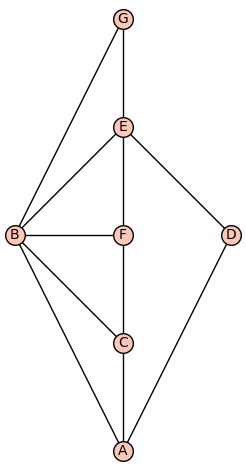

In [6]:
# Graphe exercice 2 du TD
G2 = Graph()
G2.add_edges([('A','B'),('A','C'),('A','D'),('B','C'),('B','E'),('B','F'),('B','G'),
              ('C','F'),('D','E'),('E','F'),('E','G')])
pos_G2 = {'A':(0,0), 'C':(0,2), 'F':(0,4), 'E':(0,6), 'G':(0,8), 'B':(-2,4), 'D':(2,4)}

G2.plot(pos = pos_G2)

## Exercice 3 — Contre-exemple pour DSatur

* À faire sur papier
* On vous donne le graphe ci-dessous. Vérifier le résultat de vos algorithmes sur le graphe.
* Ecrire une nouvelle version de Welsh_powell dans laquelle vous pouvez imposer un ordre et trouver un ordre qui fonctionne. 

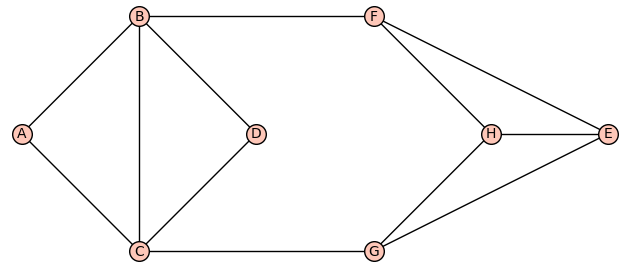

In [7]:
# Graphe contre-exemple du cours
Gce = Graph()
Gce.add_edges([('A','B'),('A','C'),('B','C'),('B','D'),('B','F'),
               ('C','D'),('C','G'),('E','F'),('E','G'),('E','H'),('F','H'),('G','H')])
pos_ce = {'A':(0,1),'B':(1,2),'C':(1,0),'D':(2,1),
          'F':(3,2),'G':(3,0),'H':(4,1),'E':(5,1)}

Gce.plot(pos = pos_ce)

## Exercice 4 — Graphe de Mycielski

* À faire sur papier
* On vous donne le graphe ci-dessous. Lancer DSatur dessus, colorier le graphe et regarder les résultats exacts que vous auriez dû obtenir. 

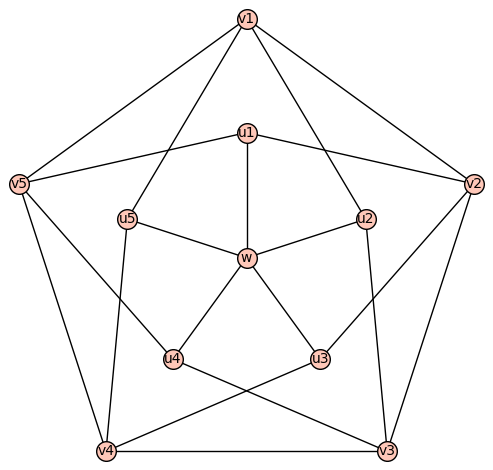

In [8]:
Gm = Graph()
# Cycle intérieur
Gm.add_edges([('v1','v2'),('v2','v3'),('v3','v4'),('v4','v5'),('v5','v1')])
# u_i adj aux voisins de v_i dans C5 (pas à v_i lui-même)
Gm.add_edges([('u1','v2'),('u1','v5'),
              ('u2','v1'),('u2','v3'),
              ('u3','v2'),('u3','v4'),
              ('u4','v3'),('u4','v5'),
              ('u5','v4'),('u5','v1')])
# w adj à tous les u_i
for i in range(1,6):
    Gm.add_edge('w', f'u{i}')

# Positions : cycle intérieur à r=2, copies à r=4, w au centre
pos_Gm = {'w': (0,0)}
for i,angle in enumerate([90,18,306,234,162]):
    rad = angle * math.pi / 180
    ri, ro = 4.2, 2.2
    pos_Gm[f'v{i+1}'] = (ri*math.cos(rad), ri*math.sin(rad))
    pos_Gm[f'u{i+1}'] = (ro*math.cos(rad), ro*math.sin(rad))

Gm.plot(pos = pos_Gm)

## Exercice 5 — Planification d'examens

* À faire sur papier
* Créer le graphe, appliquer Welsh-Powell et répondre aux questions informatiquement. 

## Exercice 6 — Allocation de fréquences radio

* À faire sur papier
* Créer le graphe et résoudre informatiquement. 

## Exercice 7 — Benchmark : comparaison systématique

* Comparer Welsh_Powell, DSatur et l'optimum exact sur des graphes aléatoires.
* Pour des graphes aléatoires on pourra utiliser par exemple G = graphs.RandomGNP(12,
0.40) qui crée un graphe aléatoire de 12 sommets avec une arête entre chaque sommets
qui existe avec probabilité 40%.